In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

from torchvision import transforms
import torchvision.models as models

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tqdm import tqdm

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cpu


In [3]:
IMAGE_DIR = "scalograms_final"
CSV_FILE = "labels_final.csv"

labels = pd.read_csv(CSV_FILE)

print(labels.shape)

labels.head()

(3153, 3)


,image,SBP,DBP
0,p10020306_83404654_83404654_0005_0.png,29.1875,24.75
1,p10020306_83404654_83404654_0005_1.png,29.1875,24.75
2,p10020306_83404654_83404654_0005_2.png,29.1875,24.75
3,p10020306_83404654_83404654_0005_3.png,29.1875,24.75
4,p10020306_83404654_83404654_0005_4.png,29.1875,24.75


In [23]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [24]:
class BPDataset(Dataset):

    def __init__(self, labels, image_dir, transform=None):

        self.labels = labels.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        img_path = os.path.join(
            self.image_dir,
            self.labels.loc[idx, "image"]
        )

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        target = torch.tensor(
            [
                self.labels.loc[idx, "SBP"],
                self.labels.loc[idx, "DBP"]
            ],
            dtype=torch.float32
        )

        return image, target

In [25]:
dataset = BPDataset(
    labels,
    IMAGE_DIR,
    transform
)

print("Dataset Size :", len(dataset))

Dataset Size : 3153


In [26]:
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

print("Train :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

Train : 2207
Validation : 472
Test : 474


In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

In [28]:
import torch
import torch.nn as nn
from torchvision import models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze early layers
for param in model.parameters():
    param.requires_grad = False

# Fine-tune the last residual block
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace the classifier for SBP & DBP regression
num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 2)
)

model = model.to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [29]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-5
)

In [30]:
EPOCHS = 20

best_loss = float("inf")

train_losses = []
val_losses = []

In [31]:
from tqdm import tqdm
import torch

for epoch in range(EPOCHS):

    # ==========================
    # Training
    # ==========================

    model.train()

    running_loss = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for images, targets in train_bar:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, targets)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        train_bar.set_postfix(
            loss=loss.item()
        )

    train_loss = running_loss / len(train_loader)

    # ==========================
    # Validation
    # ==========================

    model.eval()

    running_val = 0

    with torch.no_grad():

        for images, targets in val_loader:

            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)

            loss = criterion(outputs, targets)

            running_val += loss.item()

    val_loss = running_val / len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss = {train_loss:.4f} | "
        f"Validation Loss = {val_loss:.4f}"
    )

    # ==========================
    # Save Best Model
    # ==========================

    if val_loss < best_loss:

        best_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_bp_model.pth"
        )

        print("✅ Best model saved!")

print("\nTraining Complete!")

Epoch 1/20: 100%|██████████| 138/138 [02:11<00:00,  1.05it/s, loss=345]    


Epoch 01 | Train Loss = 5745.3934 | Validation Loss = 480.3835
✅ Best model saved!


Epoch 2/20: 100%|██████████| 138/138 [02:19<00:00,  1.01s/it, loss=386]    


Epoch 02 | Train Loss = 431.2837 | Validation Loss = 382.4851
✅ Best model saved!


Epoch 3/20: 100%|██████████| 138/138 [02:30<00:00,  1.09s/it, loss=229]   


...

Epoch 18 | Train Loss = 309.3867 | Validation Loss = 371.9586


Epoch 19/20: 100%|██████████| 138/138 [02:02<00:00,  1.13it/s, loss=175]


Epoch 19 | Train Loss = 306.6188 | Validation Loss = 364.9474


Epoch 20/20: 100%|██████████| 138/138 [02:02<00:00,  1.13it/s, loss=268]    


Epoch 20 | Train Loss = 292.0513 | Validation Loss = 356.9783

Training Complete!


In [33]:
model.load_state_dict(
    torch.load(
        "best_bp_model.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded!")

Best model loaded!


In [34]:
import numpy as np

predictions = []
ground_truth = []

model.eval()

with torch.no_grad():

    for images, targets in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions.extend(outputs.cpu().numpy())

        ground_truth.extend(targets.numpy())

predictions = np.array(predictions)
ground_truth = np.array(ground_truth)

print("Prediction Shape :", predictions.shape)
print("Ground Truth Shape :", ground_truth.shape)

Prediction Shape : (474, 2)
Ground Truth Shape : (474, 2)


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# SBP
mae_sbp = mean_absolute_error(ground_truth[:,0], predictions[:,0])
rmse_sbp = np.sqrt(mean_squared_error(ground_truth[:,0], predictions[:,0]))
r2_sbp = r2_score(ground_truth[:,0], predictions[:,0])

# DBP
mae_dbp = mean_absolute_error(ground_truth[:,1], predictions[:,1])
rmse_dbp = np.sqrt(mean_squared_error(ground_truth[:,1], predictions[:,1]))
r2_dbp = r2_score(ground_truth[:,1], predictions[:,1])

print("="*50)
print("SBP")
print("MAE  :", mae_sbp)
print("RMSE :", rmse_sbp)
print("R²   :", r2_sbp)

print("\nDBP")
print("MAE  :", mae_dbp)
print("RMSE :", rmse_dbp)
print("R²   :", r2_dbp)
print("="*50)

SBP
MAE  : 16.67853546142578
RMSE : 25.220680058965872
R²   : 0.08241879940032959

DBP
MAE  : 10.952938079833984
RMSE : 13.89034433156407
R²   : -0.01996755599975586


In [36]:
sbp_error = np.abs(predictions[:,0] - ground_truth[:,0])
dbp_error = np.abs(predictions[:,1] - ground_truth[:,1])

print("SBP ±5 mmHg  :", np.mean(sbp_error <= 5) * 100)
print("SBP ±10 mmHg :", np.mean(sbp_error <= 10) * 100)

print()

print("DBP ±5 mmHg  :", np.mean(dbp_error <= 5) * 100)
print("DBP ±10 mmHg :", np.mean(dbp_error <= 10) * 100)

SBP ±5 mmHg  : 25.738396624472575
SBP ±10 mmHg : 43.88185654008439

DBP ±5 mmHg  : 31.0126582278481
DBP ±10 mmHg : 52.742616033755276


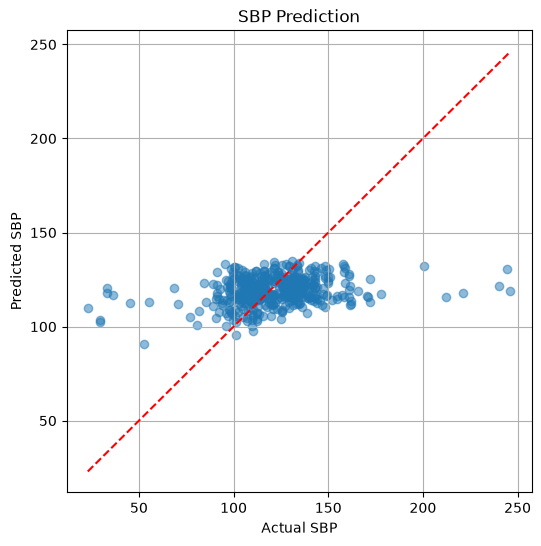

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(
    ground_truth[:,0],
    predictions[:,0],
    alpha=0.5
)

plt.plot(
    [ground_truth[:,0].min(), ground_truth[:,0].max()],
    [ground_truth[:,0].min(), ground_truth[:,0].max()],
    'r--'
)

plt.xlabel("Actual SBP")
plt.ylabel("Predicted SBP")
plt.title("SBP Prediction")
plt.grid(True)

plt.show()

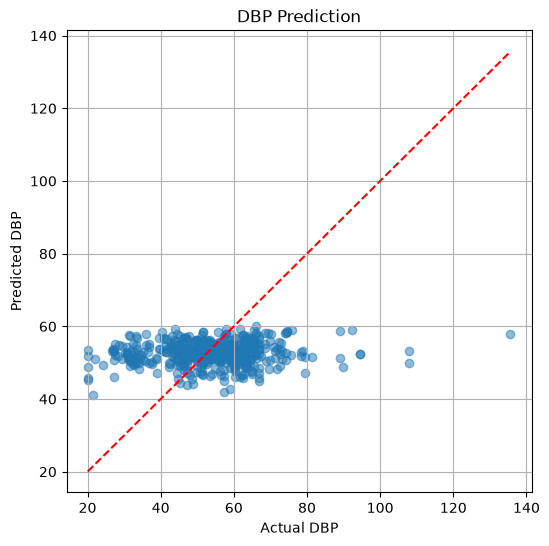

In [18]:
plt.figure(figsize=(6,6))

plt.scatter(
    ground_truth[:,1],
    predictions[:,1],
    alpha=0.5
)

plt.plot(
    [ground_truth[:,1].min(), ground_truth[:,1].max()],
    [ground_truth[:,1].min(), ground_truth[:,1].max()],
    'r--'
)

plt.xlabel("Actual DBP")
plt.ylabel("Predicted DBP")
plt.title("DBP Prediction")
plt.grid(True)

plt.show()